# EO4FLOOD flood extent: Sentinel-1, VIIRS and Sentinel-2

Three sensor examples illustrate the EO4FLOOD flood-extent products over the Niger. Sentinel-1 and
Sentinel-2 scenes are from 15 September 2020; the VIIRS composite spans 11–15 September. The sensor
sections retain their own classification meanings and legends. Each image is read directly from
the online GeoTIFF asset identified in the corresponding STAC item.

## Categorical maps and spatial extent

The products are GeoTIFF rasters, with sensor, nominal pixel size, basin and dates encoded in the
filename. Sentinel-1 and Sentinel-2 carry one acquisition date; VIIRS carries the start and end of
its composite. The final date identifies product generation.

The example rasters are in WGS 84 (EPSG:4326), so their axes are longitude and latitude. Sentinel-1
and VIIRS are distributed on a grid of about 30 m, while Sentinel-2 uses about 10 m. The VIIRS output
grid spacing does not imply that its native observation resolution equals Sentinel-1's.

Large rasters are read as display-sized first-band previews with nearest-neighbour resampling,
which preserves the categorical codes. The displayed samples are not suitable for computing
full-resolution pixel counts or flooded area. The geographic extent remains that of each source raster.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.plot import plotting_extent
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


PREVIEW_SIZE = 1200

In [2]:
def read_preview(path):
    """Read only a display-sized first band; preserve categorical pixel values."""
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"), rasterio.open(path) as source:
        scale = min(1, PREVIEW_SIZE / max(source.height, source.width))
        data = source.read(1, out_shape=(max(1, round(source.height * scale)),
                                         max(1, round(source.width * scale))),
                           resampling=Resampling.nearest)
        extent = plotting_extent(source)
        crs = source.crs
    return data, extent, crs


def plot_classes(data, extent, crs, colors, labels, ax, title):
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(len(colors) + 1) - 0.5, cmap.N)
    ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    ax.legend(handles=[Patch(facecolor=color, edgecolor="gray", label=label)
                       for color, label in zip(colors, labels)], loc="upper right")
    ax.set(title=title, xlabel=f"X ({crs})", ylabel=f"Y ({crs})")

## Sentinel-1 flood classification

The Sentinel-1 flood extent product uses the following pixel values:

- `0`: non-flooded;
- `1`: flooded, detected in a single polarization band (VV or VH);
- `2`: flooded, detected in both polarization bands;
- `255`: NoData.

Values 1 and 2 are both considered flooded pixels. Separate shades distinguish detections based
on a single polarization from detections supported by both. Sentinel-1 radar can observe through
cloud and at night.

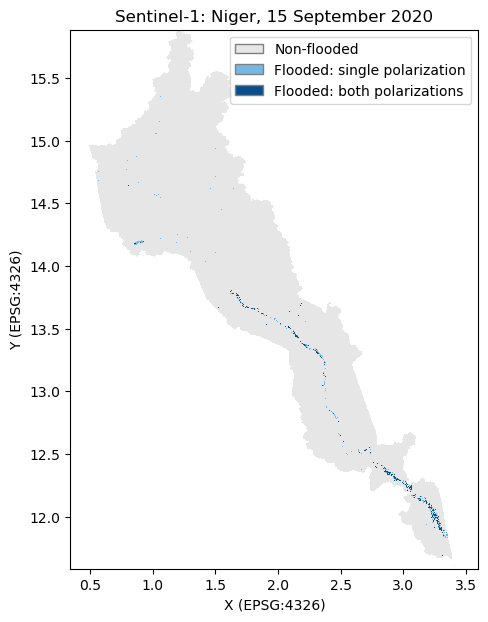

In [3]:
s1_path = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/Flood_extent/Niger/Flood_extent/From_S1/Niger_20200915/EO4FLOOD_S1_FloodedExtent_30m_nigr_20200915_20250728.tif'
s1, s1_extent, s1_crs = read_preview(s1_path)
s1 = np.ma.masked_equal(s1, 255)
fig, ax = plt.subplots(figsize=(9, 7))
plot_classes(s1, s1_extent, s1_crs, ["#e6e6e6", "#74b9e6", "#0b4f8a"], ["Non-flooded", "Flooded: single polarization", "Flooded: both polarizations"], ax, "Sentinel-1: Niger, 15 September 2020")
plt.show()

## VIIRS flood composite

VIIRS uses `200` for flooded pixels and `0` for NoData. Other valid codes—including normal open
water, cloud and snow—are grouped as non-flooded for this binary display. The map therefore describes
flood detections rather than all the conditions VIIRS observed.

VIIRS composites several days. This example covers 11–15 September 2020; the final date in its
filename is the processing date rather than an additional observation date.

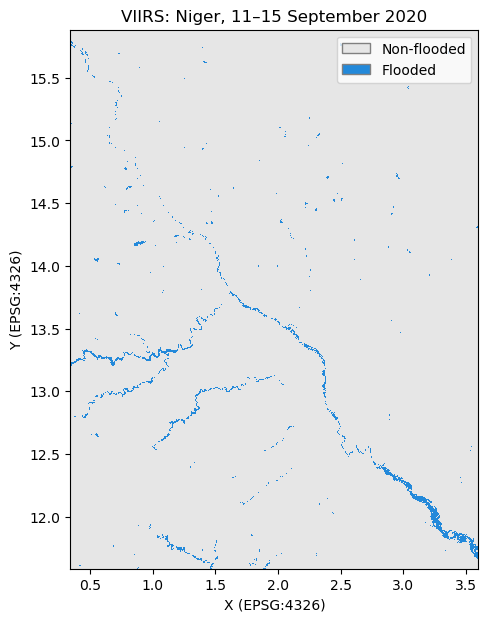

In [4]:
viirs_path = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/Flood_extent/Niger/Flood_extent/From_VIIRS/Niger_2020-09-10_2020-09-20_01th/EO4FLOOD_VIIRS_FloodedExtent_30m_nigr_20200911_20200915_20250728.tif'
viirs, extent, crs = read_preview(viirs_path)
classes = np.ma.array((viirs == 200).astype(int), mask=viirs == 0)
fig, ax = plt.subplots(figsize=(9, 7))
plot_classes(classes, extent, crs, ["#e6e6e6", "#2389da"], ["Non-flooded", "Flooded"], ax,
             "VIIRS: Niger, 11–15 September 2020")
plt.show()

## Sentinel-2 water classification

The Sentinel-2 product uses `0` for NoData, `1` for other land cover, `2` for water, and `3` for cloud.
Other land cover includes vegetation, bare soil and urban areas. Water and cloud receive separate colours;
NoData is transparent.

Sentinel-2 shows water, not flooding alone. Its water class includes permanent rivers and lakes.
A change relative to a water map outside an event is needed to attribute newly inundated areas.
Optical observations can be obscured by cloud.

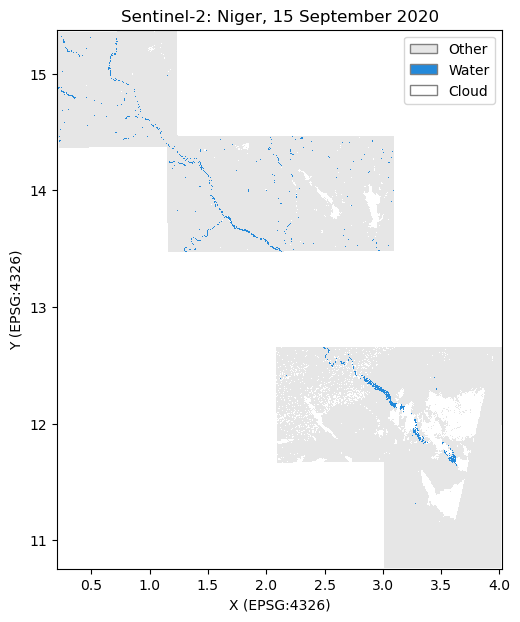

In [5]:
s2_path = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/Flood_extent/Niger/Flood_extent/From_S2/EO4FLOOD_S2_Flood_Extent_10m_nigr_20200915_20250701.tif'
s2, s2_extent, s2_crs = read_preview(s2_path)
s2 = np.ma.masked_equal(s2, 0) - 1
fig, ax = plt.subplots(figsize=(9, 7))
plot_classes(s2, s2_extent, s2_crs, ["#e6e6e6", "#2389da", "white"], ["Other", "Water", "Cloud"], ax, "Sentinel-2: Niger, 15 September 2020")
plt.show()

## Reading the three maps together

Sentinel-1 sees through cloud and works at night, Sentinel-2 identifies water and cloud in an
optical image, and VIIRS combines observations over several days. The two VIIRS display classes
omit distinctions that remain in its underlying product. Different sensor physics, observation
windows, native resolutions and footprints explain why their maps need not agree pixel for pixel.
NoData is transparent in every view.